# Produtor e falha selante — volumes finitos

Simulação com produtor fora do centro e falha vertical representada por faces internas de fluxo nulo. A geometria e a posição reutilizam a configuração existente no notebook MDF correspondente.

Vazão positiva representa entrada no reservatório; a produção aparece negativa. O solver fornece a pressão e a vazão do produtor, e o módulo calcula as velocidades nas células a partir dos gradientes entre volumes. O balanço de massa por passo e global é calculado abaixo.

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt

from core.permeabilidade2d import carregar_permeabilidade, gerar_permeabilidade, salvar_permeabilidade
from mvf.implicita_2d import implicita_2d
from core.velocidade2d import calcular_velocidade

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10})


In [2]:
p0 = 20.684e6
pwf = 15.0e6
Lx = Ly = 1000.0
h = 30.0
rw = 0.10
phi = 0.22
ct = 3.046e-9
mu = 1.0e-3
t_d = 10
nx = ny = 21
nt = 500

t_final = t_d * 86400
permeabilidade_file = ROOT / "data" / "permeabilidade.csv"
if permeabilidade_file.exists():
    k_mD = carregar_permeabilidade(permeabilidade_file)
else:
    k_mD = gerar_permeabilidade(nx, ny, 50, 500, seed=42)
    salvar_permeabilidade(k_mD, permeabilidade_file)
k = k_mD * 9.869233e-16
iw = 5
jw = 10
i_falha = 13
j_inicio = 5
j_fim = 15
internal_no_flow_faces = [
    (j * nx + i_falha - 1, j * nx + i_falha)
    for j in range(j_inicio, j_fim + 1)
]

RESULTS_DIR = ROOT / "results" / "mvf" / "falha_produtor"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

x, y, t, P, q_produtor = implicita_2d(
    p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt,
    iw=iw, jw=jw, internal_no_flow_faces=internal_no_flow_faces,
)
Vx, Vy, V = calcular_velocidade(
    P, k, mu, Lx / nx, Ly / ny, internal_no_flow_faces=internal_no_flow_faces, h=h,
)
q_producao = np.maximum(-q_produtor, 0.0)
Q_acumulada = np.zeros_like(t)
Q_acumulada[1:] = np.cumsum(0.5 * (q_producao[:-1] + q_producao[1:]) * np.diff(t))


Maior resíduo absoluto por passo: 1.744809e-10 m³
Resíduo global ao final: -4.422073e-09 m³
Variação armazenada ao final: -1.796676e+04 m³
Volume líquido acumulado: -1.796676e+04 m³


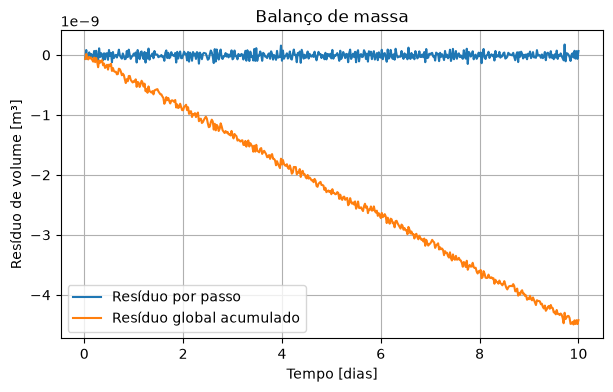

In [3]:
# Balanço de massa por passo e acumulado
# Vazões positivas entram; q_produtor é negativo quando há produção.
# As fronteiras externas são seladas e, no caso da falha, as faces internas também não têm fluxo.
volume_celula = (Lx / nx) * (Ly / ny) * h
armazenamento = phi * ct * volume_celula * (P.sum(axis=(1, 2)) - P[0].sum())
vazao_liquida = q_produtor
dt_passos = np.diff(t)
volume_liquido_passo = vazao_liquida[1:] * dt_passos
variacao_armazenada_passo = np.diff(armazenamento)
residuo_passo = variacao_armazenada_passo - volume_liquido_passo
residuo_global = np.cumsum(residuo_passo)

print(f"Maior resíduo absoluto por passo: {np.max(np.abs(residuo_passo)):.6e} m³")
print(f"Resíduo global ao final: {residuo_global[-1]:.6e} m³")
print(f"Variação armazenada ao final: {armazenamento[-1]:.6e} m³")
print(f"Volume líquido acumulado: {np.sum(volume_liquido_passo):.6e} m³")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t[1:] / 86400, residuo_passo, label="Resíduo por passo")
ax.plot(t[1:] / 86400, residuo_global, label="Resíduo global acumulado")
ax.set(xlabel="Tempo [dias]", ylabel="Resíduo de volume [m³]", title="Balanço de massa")
ax.grid()
ax.legend()
fig.savefig(RESULTS_DIR / "balanco_massa.pdf", bbox_inches="tight")
plt.show()


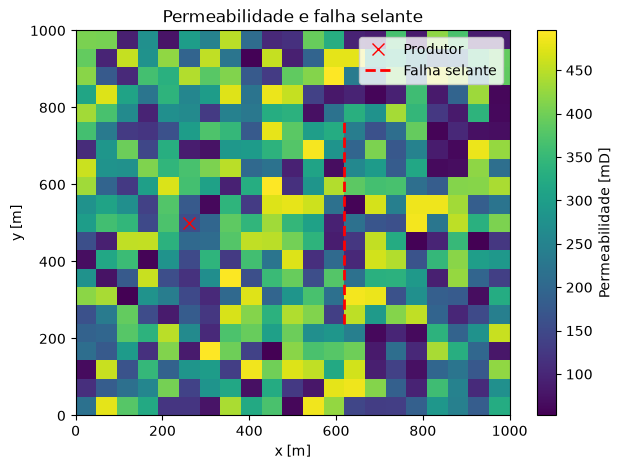

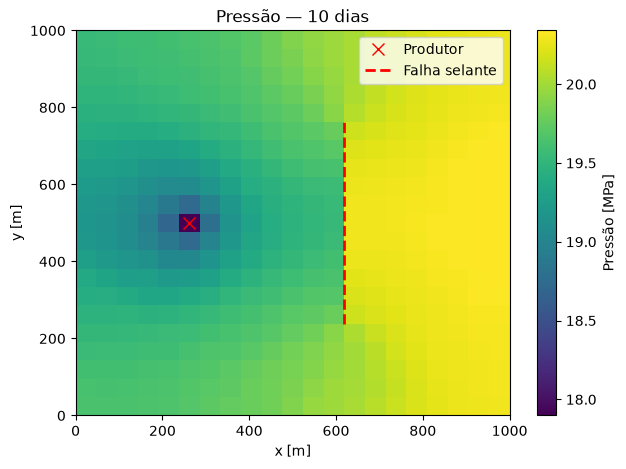

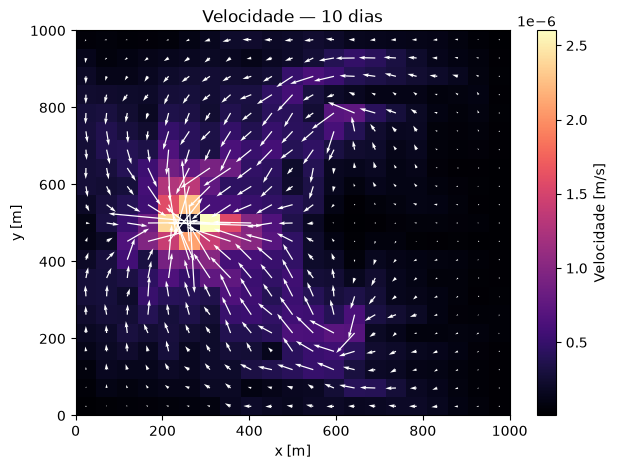

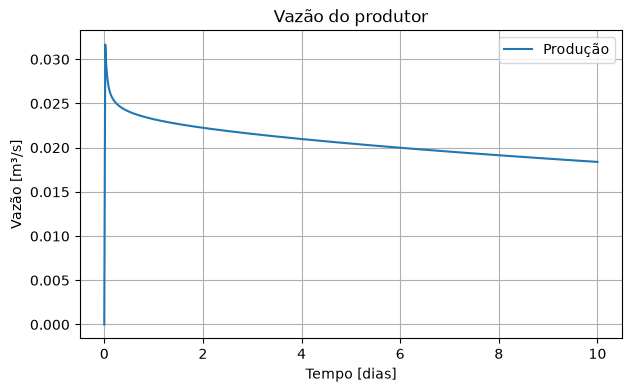

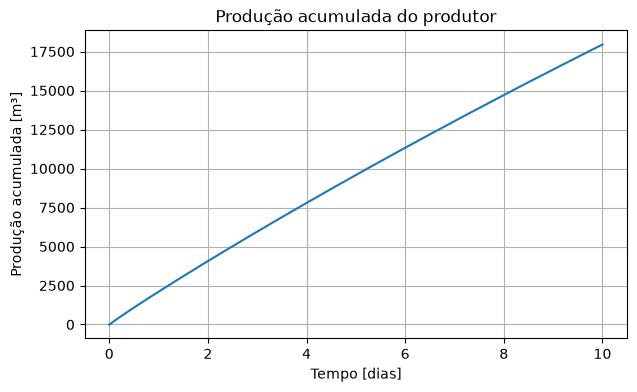

In [4]:
X, Y = np.meshgrid(x, y)
x_falha = i_falha * (Lx / nx)
y_falha = np.array([j_inicio, j_fim + 1]) * (Ly / ny)

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.pcolormesh(X, Y, k_mD, shading="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="Permeabilidade [mD]")
ax.plot(x[iw], y[jw], "rx", markersize=9, label="Produtor")
ax.plot([x_falha, x_falha], y_falha, "r--", linewidth=2, label="Falha selante")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Permeabilidade e falha selante")
ax.legend()
fig.savefig(RESULTS_DIR / "permeabilidade_falha.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.pcolormesh(X, Y, P[-1] / 1e6, shading="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="Pressão [MPa]")
ax.plot(x[iw], y[jw], "rx", markersize=9, label="Produtor")
ax.plot([x_falha, x_falha], y_falha, "r--", linewidth=2, label="Falha selante")
ax.set(xlabel="x [m]", ylabel="y [m]", title=f"Pressão — {t[-1] / 86400:g} dias")
ax.legend()
fig.savefig(RESULTS_DIR / "pressao_final.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.pcolormesh(X, Y, V[-1], shading="auto", cmap="magma")
fig.colorbar(image, ax=ax, label="Velocidade [m/s]")
step = max(1, nx // 12)
ax.quiver(X[::step, ::step], Y[::step, ::step], Vx[-1, ::step, ::step], Vy[-1, ::step, ::step], color="white")
ax.set(xlabel="x [m]", ylabel="y [m]", title=f"Velocidade — {t[-1] / 86400:g} dias")
fig.savefig(RESULTS_DIR / "velocidade_final.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t / 86400, q_producao, label="Produção")
ax.set(xlabel="Tempo [dias]", ylabel="Vazão [m³/s]", title="Vazão do produtor")
ax.grid()
ax.legend()
fig.savefig(RESULTS_DIR / "vazao_produtor.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t / 86400, Q_acumulada)
ax.set(xlabel="Tempo [dias]", ylabel="Produção acumulada [m³]", title="Produção acumulada do produtor")
ax.grid()
fig.savefig(RESULTS_DIR / "producao_acumulada.pdf", bbox_inches="tight")
plt.show()


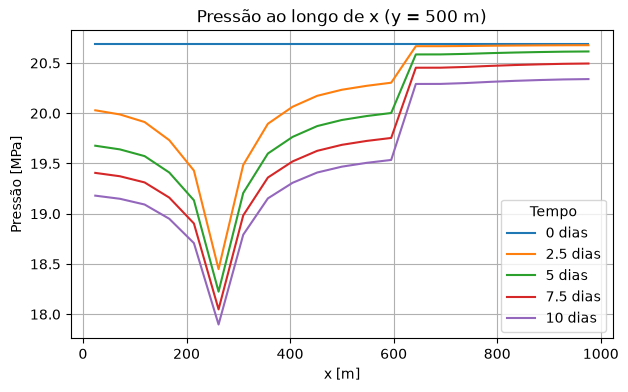

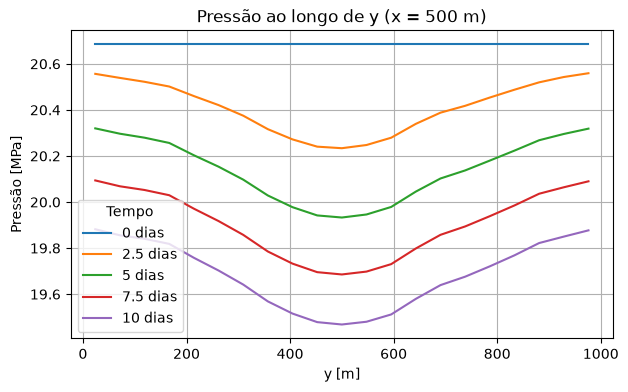

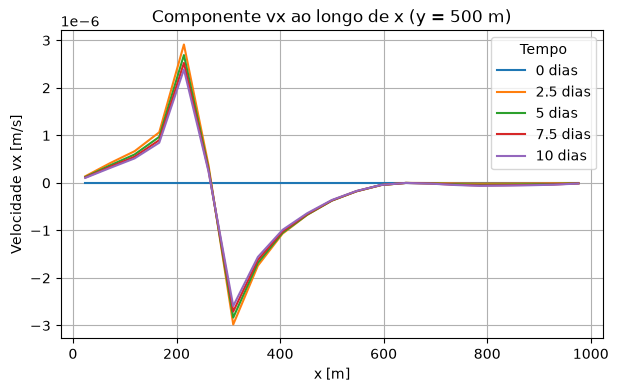

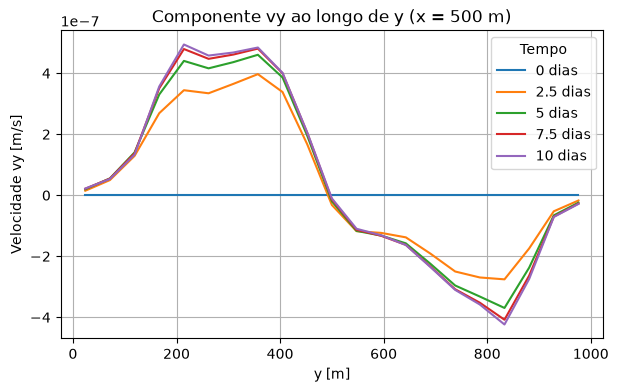

In [5]:
# Perfis transientes ao longo das linhas centrais do reservatório
indices_tempo = np.unique(np.linspace(0, len(t) - 1, 5, dtype=int))
j_central = ny // 2
i_central = nx // 2

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(x, P[indice, j_central, :] / 1e6, label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="x [m]", ylabel="Pressão [MPa]", title=f"Pressão ao longo de x (y = {y[j_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "pressao_transiente_x.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(y, P[indice, :, i_central] / 1e6, label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="y [m]", ylabel="Pressão [MPa]", title=f"Pressão ao longo de y (x = {x[i_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "pressao_transiente_y.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(x, Vx[indice, j_central, :], label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="x [m]", ylabel="Velocidade vx [m/s]", title=f"Componente vx ao longo de x (y = {y[j_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "velocidade_transiente_x.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(y, Vy[indice, :, i_central], label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="y [m]", ylabel="Velocidade vy [m/s]", title=f"Componente vy ao longo de y (x = {x[i_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "velocidade_transiente_y.pdf", bbox_inches="tight")
plt.show()
